In [31]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)

In [32]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/diabetes_risk_20000.csv")

In [33]:
df.head()

,Age,BMI,Glucose,BloodPressure,Insulin,FamilyHistory,PhysicalActivity,Smoking,WaistCircumference,DiabetesRisk
0,36,29.4,93,74,49,yes,moderate,no,55.0,No
1,67,32.1,78,77,61,no,high,yes,64.4,No
2,42,20.6,117,73,109,no,high,no,55.0,No
3,56,27.0,119,94,92,no,high,no,55.0,No
4,47,15.0,141,55,40,yes,low,yes,55.0,No


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 20000 non-null  int64  
 1   BMI                 20000 non-null  float64
 2   Glucose             20000 non-null  int64  
 3   BloodPressure       20000 non-null  int64  
 4   Insulin             20000 non-null  int64  
 5   FamilyHistory       20000 non-null  object 
 6   PhysicalActivity    20000 non-null  object 
 7   Smoking             20000 non-null  object 
 8   WaistCircumference  20000 non-null  float64
 9   DiabetesRisk        20000 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 1.5+ MB


In [35]:
df.shape

(20000, 10)

In [36]:
df.columns

Index(['Age', 'BMI', 'Glucose', 'BloodPressure', 'Insulin', 'FamilyHistory',
       'PhysicalActivity', 'Smoking', 'WaistCircumference', 'DiabetesRisk'],
      dtype='object')

In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df.isnull().sum()

Age                   0
BMI                   0
Glucose               0
BloodPressure         0
Insulin               0
FamilyHistory         0
PhysicalActivity      0
Smoking               0
WaistCircumference    0
DiabetesRisk          0
dtype: int64

In [39]:
df.describe()

,Age,BMI,Glucose,BloodPressure,Insulin,WaistCircumference
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,49.140850,27.550090,112.143950,77.896800,100.145250,56.334255
std,18.238677,5.127721,27.644264,12.007421,71.959672,3.536233
min,18.000000,15.000000,55.000000,40.000000,10.000000,55.000000
25%,33.000000,24.100000,93.000000,70.000000,52.000000,55.000000
50%,49.000000,27.600000,112.000000,78.000000,81.000000,55.000000
75%,65.000000,31.000000,131.000000,86.000000,126.000000,55.000000
max,80.000000,49.100000,216.000000,127.000000,800.000000,88.300000


In [40]:
df["DiabetesRisk"].value_counts()

DiabetesRisk
No     18932
Yes     1068
Name: count, dtype: int64

In [41]:
df["FamilyHistory"].value_counts()

FamilyHistory
no     13576
yes     6424
Name: count, dtype: int64

In [42]:
df["PhysicalActivity"].value_counts()

PhysicalActivity
moderate    9005
low         6930
high        4065
Name: count, dtype: int64

In [43]:
df["Smoking"].value_counts()

Smoking
no     15551
yes     4449
Name: count, dtype: int64

# Separate Features and Target

In [44]:
X=df.drop(columns="DiabetesRisk",axis=1)
y=df["DiabetesRisk"]

In [45]:
print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (20000, 9)
Y Shape: (20000,)


In [46]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)
print("Classes:", le.classes_)
print(dict(zip(le.classes_, le.transform(le.classes_))))

Classes: ['No' 'Yes']
{'No': np.int64(0), 'Yes': np.int64(1)}


In [47]:
numerical_cal=X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorcal_cal=X.select_dtypes(include=["object"]).columns.tolist()

In [48]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_test.shape)
print(X_train.shape)
print(y_train.shape)
print(y_test.shape)

(4000, 9)
(16000, 9)
(16000,)
(4000,)


# Apply OneHotEncoder and StandardScaler
- StandardScaler → Numerical columns
- OneHotEncoder → Categorical columns

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [50]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cal),
        ("cat", OneHotEncoder(handle_unknown="ignore"),categorcal_cal)])

# Build KNN Pipeline

In [53]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())])
knn_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Age','BMI','Glucose',...,'PhysicalActivity','Smoking', 'WaistCircumference']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthroug

In [54]:
y_pred=knn_model.predict(X_test)

In [55]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.944


In [56]:
print("Precision:", precision_score(y_test, y_pred, zero_division=0))

Precision: 0.23529411764705882


In [57]:
print("Recall:", recall_score(y_test, y_pred, zero_division=0))

Recall: 0.018604651162790697


In [58]:
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

F1 Score: 0.034482758620689655


In [59]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_,
    zero_division=0))

              precision    recall  f1-score   support

          No       0.95      1.00      0.97      3785
         Yes       0.24      0.02      0.03       215

    accuracy                           0.94      4000
   macro avg       0.59      0.51      0.50      4000
weighted avg       0.91      0.94      0.92      4000



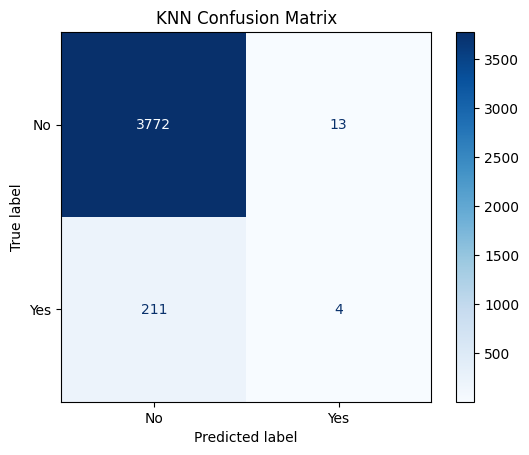

In [60]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot(cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()

In [61]:
y_prob = knn_model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ROC-AUC: 0.5893760560351448


# Hyperparameter Tuning – RandomizedSearchCV

In [62]:
param_dist = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 13, 15, 17],
    "classifier__weights": ["uniform", "distance"],
    "classifier__metric": ["euclidean", "manhattan", "minkowski"],
    "classifier__p": [1, 2]}

In [63]:
random_search = RandomizedSearchCV(
    estimator=knn_model,
    param_distributions=param_dist,
    n_iter=12,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1)
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__metric': ['euclidean', 'manhattan', ...], 'classifier__n_neighbors': [3, 5, ...], 'classifier__p': [1, 2], 'classifier__weights': ['uniform', 'distance']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` c

In [64]:
print("Best Parameters:", random_search.best_params_)

Best Parameters: {'classifier__weights': 'distance', 'classifier__p': 1, 'classifier__n_neighbors': 3, 'classifier__metric': 'manhattan'}


In [65]:
print("Best CV F1 Score:", random_search.best_score_)

Best CV F1 Score: 0.05971024427240818


In [66]:
best_model = random_search.best_estimator_
y_pred_best = best_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_best, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_best, zero_division=0))

Accuracy: 0.93875
Precision: 0.17391304347826086
Recall: 0.037209302325581395
F1 Score: 0.06130268199233716


In [67]:
best_params = random_search.best_params_
best_k = best_params["classifier__n_neighbors"]
param_grid = {
    "classifier__n_neighbors": sorted(set([
        max(1, best_k - 2),
        best_k,
        best_k + 2
    ])),

    "classifier__weights": [
        best_params["classifier__weights"]
    ],

    "classifier__metric": [
        best_params["classifier__metric"]
    ],

    "classifier__p": [
        best_params["classifier__p"]
]}

In [68]:
grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 3 candidates, totalling 9 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__metric': ['manhattan'], 'classifier__n_neighbors': [1, 3, ...], 'classifier__p': [1], 'classifier__weights': ['distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_gl

In [69]:
print("Best Grid Parameters:", grid_search.best_params_)
print("Best Grid CV Score:", grid_search.best_score_)

Best Grid Parameters: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 1, 'classifier__p': 1, 'classifier__weights': 'distance'}
Best Grid CV Score: 0.09468979138273158


In [70]:
final_model = grid_search.best_estimator_
final_pred = final_model.predict(X_test)
print("Final Accuracy:", accuracy_score(y_test, final_pred))
print("Final Precision:", precision_score(y_test, final_pred, zero_division=0))
print("Final Recall:", recall_score(y_test, final_pred, zero_division=0))
print("Final F1 Score:", f1_score(y_test, final_pred, zero_division=0))

Final Accuracy: 0.9075
Final Precision: 0.1065989847715736
Final Recall: 0.09767441860465116
Final F1 Score: 0.10194174757281553


In [71]:
print(classification_report(
    y_test,
    final_pred,
    target_names=le.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

          No       0.95      0.95      0.95      3785
         Yes       0.11      0.10      0.10       215

    accuracy                           0.91      4000
   macro avg       0.53      0.53      0.53      4000
weighted avg       0.90      0.91      0.91      4000



In [72]:
new_person = pd.DataFrame([{
    "Age": 35,
    "BMI": 28.5,
    "Glucose": 130,
    "BloodPressure": 80,
    "Insulin": 120,
    "FamilyHistory": "yes",
    "PhysicalActivity": "low",
    "Smoking": "no",
    "WaistCircumference": 95.0
}])

In [73]:
prediction = final_model.predict(new_person)
result = le.inverse_transform(prediction)
print("Predicted Diabetes Risk:", result[0])

Predicted Diabetes Risk: No


In [75]:
import joblib
joblib.dump(final_model, "diabetes_knn_model.pkl")
joblib.dump(le, "diabetes_label_encoder.pkl")
print("Model saved successfully!")

Model saved successfully!


In [76]:
loaded_model = joblib.load("diabetes_knn_model.pkl")
loaded_encoder = joblib.load("diabetes_label_encoder.pkl")

In [77]:
prediction = loaded_model.predict(new_person)
result = loaded_encoder.inverse_transform(prediction)
print("Predicted Diabetes Risk:", result[0])

Predicted Diabetes Risk: No
